# Self-Driving Car: Behavioral Cloning (Kaggle)
Camera image -> steering angle, PilotNet-style CNN.

**Lake-track version.** Fixes: labels smoothed *before* balancing (time order kept), interleaved-block train/val split, validation on center camera only, balancing on train only, side-camera correction 0.1, MSE loss.

In [13]:
import os, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [14]:
DATA_DIR   = "/kaggle/input/datasets/kamatchinathangogul/udacity-self-driving-car-lake/self_driving_car_dataset_lake"   # use Copy path if different
CSV        = os.path.join(DATA_DIR, "driving_log.csv")
CORRECTION = 0.1        # side-camera steering offset
H, W       = 66, 200
BS         = 64
SMOOTH     = 15         # rolling-mean window (keyboard steering is step-like)

## 1. Load, smooth, split, balance

track
self_driving_car    6113
Name: count, dtype: int64


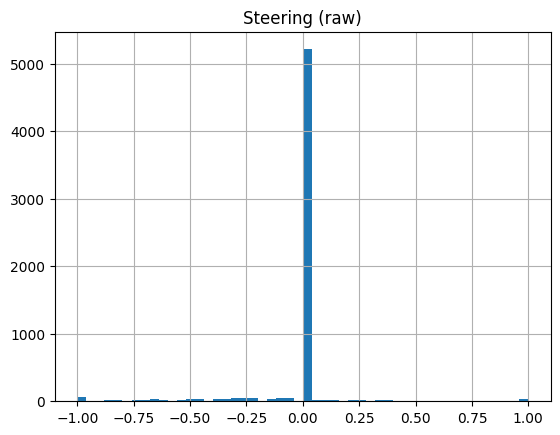

In [15]:
cols = ["center", "left", "right", "steering", "throttle", "brake", "speed"]
df = pd.read_csv(CSV, header=None, names=cols, skiprows=0)   # simulator CSV has no header row.reset_index(drop=True)

def img_path(p):
    name = p.strip().replace("\\", "/").split("/")[-1]
    return os.path.join(DATA_DIR, "IMG", name)

# track id from folder name in the image path
df["track"] = df.center.str.replace("\\", "/", regex=False).str.split("/").str[-3]
print(df.track.value_counts())

df.steering.hist(bins=50); plt.title("Steering (raw)"); plt.show()

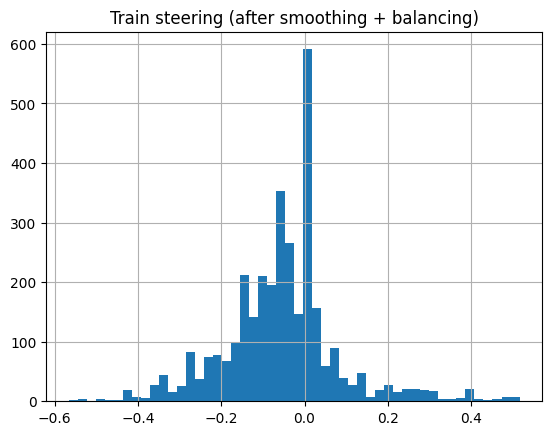

train: 10002 val: 1200
('/kaggle/input/datasets/kamatchinathangogul/udacity-self-driving-car-lake/self_driving_car_dataset_lake/IMG/center_2026_10_29_13_11_37_815.jpg', -0.04666666666666666)
True


In [16]:
# 1) Smooth labels in ORIGINAL time order, per track (before any shuffling/balancing)
df["steering"] = (df.groupby("track")["steering"]
                    .transform(lambda s: s.rolling(SMOOTH, center=True, min_periods=1).mean()))

# 2) Interleaved 200-frame blocks: every 5th block is validation (val contains turns too)
df = df.reset_index(drop=True)
df["blk"] = np.arange(len(df)) // 200
tr, va = df[df.blk % 5 != 4], df[df.blk % 5 == 4]

# 3) Balance TRAIN only: keep 30% of near-zero steering frames
zero = tr[tr.steering.abs() < 0.02]
tr = pd.concat([tr[tr.steering.abs() >= 0.02], zero.sample(frac=0.3, random_state=1)])

tr.steering.hist(bins=50); plt.title("Train steering (after smoothing + balancing)"); plt.show()

# 4) Samples: side cameras for train only; val = center camera only (real labels)
def make_samples(d, side):
    s = []
    for r in d.itertuples():
        s.append((img_path(r.center), r.steering))
        if side:
            s.append((img_path(r.left),  r.steering + CORRECTION))
            s.append((img_path(r.right), r.steering - CORRECTION))
    return s

train_s, val_s = make_samples(tr, True), make_samples(va, False)
print("train:", len(train_s), "val:", len(val_s))
print(train_s[0]); print(os.path.exists(train_s[0][0]))   # must print True

## 2. Preprocessing, augmentation, generator

In [17]:
def preprocess(img):
    img = img[60:-25, :, :]
    img = cv2.resize(img, (W, H))
    img = cv2.cvtColor(img, cv2.COLOR_RGB2YUV)
    return img            # scaling handled inside the model (Rescaling layer)

def augment(img, angle):
    if np.random.rand() < 0.5:
        img, angle = cv2.flip(img, 1), -angle
    if np.random.rand() < 0.5:
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
        hsv[..., 2] *= np.random.uniform(0.5, 1.2)
        img = cv2.cvtColor(np.clip(hsv, 0, 255).astype(np.uint8), cv2.COLOR_HSV2RGB)
    return img, angle

def generator(data, bs=BS, train=True):
    data = list(data)
    while True:
        if train: np.random.shuffle(data)
        for i in range(0, len(data), bs):
            X, y = [], []
            for p, a in data[i:i + bs]:
                img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
                if train:
                    img, a = augment(img, a)
                X.append(preprocess(img))
                y.append(np.clip(a, -1, 1))
            yield np.array(X, np.float32), np.array(y, np.float32)

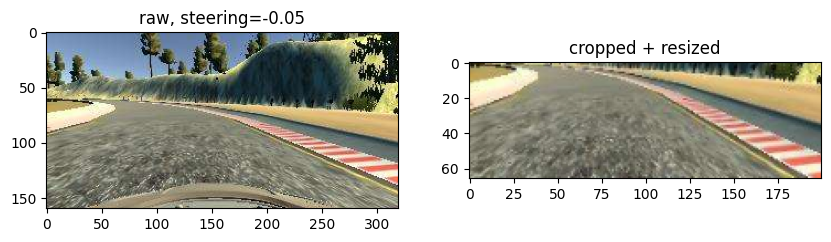

In [18]:
p, a = train_s[0]
raw = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].imshow(raw); ax[0].set_title(f"raw, steering={a:.2f}")
ax[1].imshow(cv2.cvtColor(preprocess(raw), cv2.COLOR_YUV2RGB)); ax[1].set_title("cropped + resized")
plt.show()

## 3. Model

In [19]:
keras.backend.clear_session()
model = keras.Sequential([
    layers.Input((H, W, 3)),
    layers.Rescaling(1 / 127.5, offset=-1),
    layers.Conv2D(24, 5, strides=2, activation="elu"),
    layers.BatchNormalization(),
    layers.Conv2D(36, 5, strides=2, activation="elu"),
    layers.BatchNormalization(),
    layers.Conv2D(48, 5, strides=2, activation="elu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, 3, activation="elu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, 3, activation="elu"),
    layers.Flatten(),
    layers.Dropout(0.2),
    layers.Dense(100, activation="elu"),
    layers.Dropout(0.1),
    layers.Dense(50, activation="elu"),
    layers.Dense(10, activation="elu"),
    layers.Dense(1),
])
model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 66, 200, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 31, 98, 24)     │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 31, 98, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 47, 36)     │        21,636 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 47, 36)     │           144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 5, 22, 48)      │        43,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 5, 22, 48)      │           192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 20, 64)      │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 3, 20, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 1, 18, 64)      │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       115,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,907 (987.92 KB)

 Trainable params: 252,563 (986.57 KB)

 Non-trainable params: 344 (1.34 KB)

## 4. Train

In [20]:
from tensorflow.keras import callbacks as kcb
hist = model.fit(
    generator(train_s, BS, train=True),
    steps_per_epoch=len(train_s) // BS,
    validation_data=generator(val_s, BS, train=False),
    validation_steps=max(1, len(val_s) // BS),
    epochs=60,
    callbacks=[kcb.EarlyStopping(patience=8, restore_best_weights=True),
               kcb.ReduceLROnPlateau(factor=0.5, patience=3),
               kcb.ModelCheckpoint("model.keras", save_best_only=True)])

Epoch 1/60
156/156 ━━━━━━━━━━━━━━━━━━━━ 282s 2s/step - loss: 0.3862 - mae: 0.4361 - val_loss: 0.0333 - val_mae: 0.1358 - learning_rate: 1.0000e-04
Epoch 2/60
156/156 ━━━━━━━━━━━━━━━━━━━━ 50s 323ms/step - loss: 0.0719 - mae: 0.2004 - val_loss: 0.0084 - val_mae: 0.0694 - learning_rate: 1.0000e-04
Epoch 3/60
156/156 ━━━━━━━━━━━━━━━━━━━━ 49s 314ms/step - loss: 0.0448 - mae: 0.1585 - val_loss: 0.0064 - val_mae: 0.0652 - learning_rate: 1.0000e-04
Epoch 4/60
156/156 ━━━━━━━━━━━━━━━━━━━━ 49s 315ms/step - loss: 0.0341 - mae: 0.1398 - val_loss: 0.0053 - val_mae: 0.0577 - learning_rate: 1.0000e-04
Epoch 5/60
156/156 ━━━━━━━━━━━━━━━━━━━━ 49s 312ms/step - loss: 0.0266 - mae: 0.1242 - val_loss: 0.0050 - val_mae: 0.0575 - learning_rate: 1.0000e-04
Epoch 6/60
156/156 ━━━━━━━━━━━━━━━━━━━━ 49s 312ms/step - loss: 0.0237 - mae: 0.1159 - val_loss: 0.0049 - val_mae: 0.0568 - learning_rate: 1.0000e-04
Epoch 7/60
156/156 ━━━━━━━━━━━━━━━━━━━━ 49s 313ms/step - loss: 0.0212 - mae: 0.1106 - val_loss: 0.0037 - val

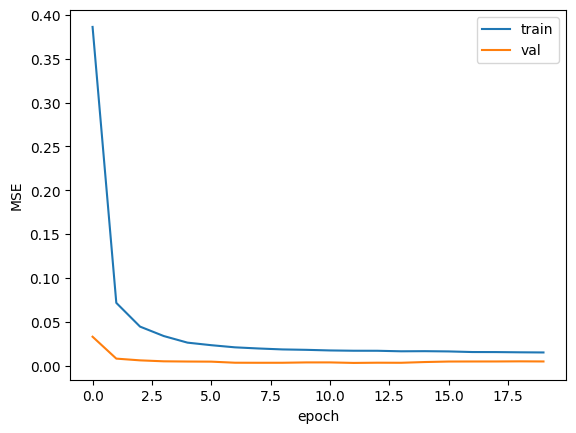

In [21]:
plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

## 5. Evaluate (center-camera validation frames)

baseline MAE (predict 0): 0.037925005
MSE : 0.004423009697347879
RMSE: 0.06650571176483926
MAE : 0.049865126609802246
R2  : 0.14476239681243896
turn-frame MAE: 0.071364306 | baseline: 0.13969074


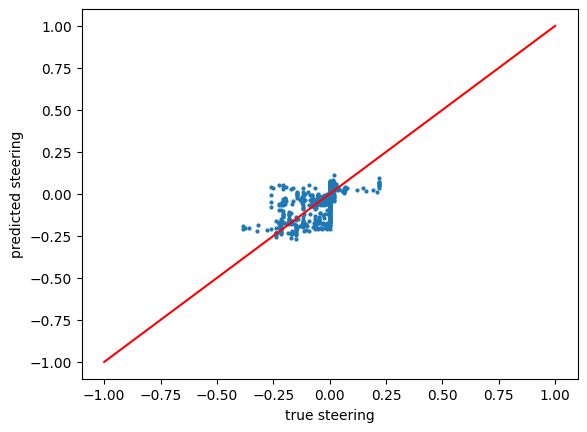

In [22]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

vg = generator(val_s, BS, train=False)
preds, trues = [], []
for _ in range(int(np.ceil(len(val_s) / BS))):
    X, y = next(vg)
    preds.append(model.predict(X, verbose=0).ravel()); trues.append(y)
yv, pred = np.concatenate(trues)[:len(val_s)], np.concatenate(preds)[:len(val_s)]

print("baseline MAE (predict 0):", np.mean(np.abs(yv)))
print("MSE :", mean_squared_error(yv, pred))
print("RMSE:", np.sqrt(mean_squared_error(yv, pred)))
print("MAE :", mean_absolute_error(yv, pred))
print("R2  :", r2_score(yv, pred))
m = np.abs(yv) > 0.05
print("turn-frame MAE:", np.mean(np.abs(yv[m] - pred[m])), "| baseline:", np.mean(np.abs(yv[m])))

plt.scatter(yv, pred, s=4); plt.plot([-1, 1], [-1, 1], "r")
plt.xlabel("true steering"); plt.ylabel("predicted steering")
plt.savefig("pred_vs_true.png", dpi=150, bbox_inches="tight"); plt.show()

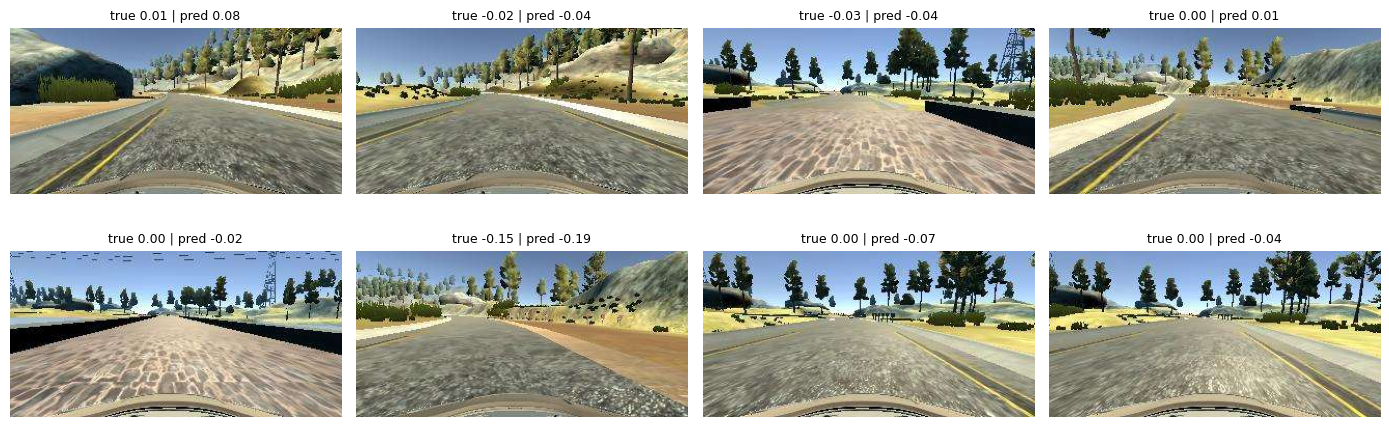

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, i in zip(axes.ravel(), np.linspace(0, len(val_s) - 1, 8).astype(int)):
    p, a = val_s[i]
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    pr = model.predict(preprocess(img)[None], verbose=0)[0, 0]
    ax.imshow(img); ax.axis("off"); ax.set_title(f"true {a:.2f} | pred {pr:.2f}", fontsize=9)
plt.tight_layout(); plt.show()